# Per-Band Classifier Selection for Movement vs. Rest EEG Decoding

## Abstract
Brain-computer interface (BCI) decoding depends on both the frequency band
and the classifier. We study movement vs. rest classification on an 8-channel
EEG (C3, C4, Cz, Fz, PO7, PO8, Pz, Oz, 250 Hz) for 20 subjects. The signal is
split into nine 4 Hz sub-bands (4-8 Hz up to 36-40 Hz) and epoched 0.5-4.5 s
after each cue. For each band we compare two pipelines: Common Spatial
Patterns with Linear Discriminant Analysis (CSP+LDA), and a Riemannian
tangent-space pipeline (Ledoit-Wolf covariance, tangent space, scaling,
logistic regression). Using repeated shuffle-split cross-validation on each
subject's training sessions, we select the better pipeline for every band.
The selected per-band classifiers are then combined in a weighted ensemble
and evaluated on a held-out single-subject test set. Mean cross-validated
accuracy was **[X]%** for the best single band and **[Y]%** for the weighted
ensemble across subjects.

## 1. Setup
Imports, recording parameters and the two candidate classifiers.

- **Data:** 8 EEG channels, sampled at 250 Hz.
- **Sub-bands:** nine 4 Hz bands from 4-8 Hz to 36-40 Hz.
- **Candidate pipelines:**
  - `CSP(4 components, Ledoit-Wolf) -> LDA`
  - `Covariances(LWF) -> TangentSpace(Riemann) -> StandardScaler -> LogisticRegression`
- **Validation:** `ShuffleSplit`, 80/20 split, fixed seed for reproducibility.

In [1]:
#Imports
import os
import mne
import math
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#Sci-kit learn basic imports
from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin,clone
from sklearn.pipeline import Pipeline,make_pipeline
from sklearn.model_selection import cross_val_score, ShuffleSplit

#CSP + LDA pipelines
from mne.decoding import CSP
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA

#Riemannian Tangent Space pipelines
from pyriemann.estimation import Covariances
from pyriemann.tangentspace import TangentSpace
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

mne.set_log_level("WARNING")

#Variable & Constant
result = []
SFREQ = 250 #Frequency of the eeg
ch_names = ['C4', 'C3', 'Cz','Fz','PO7','Pz','PO8','Oz'] #Channels used in the eeg
cv = ShuffleSplit(test_size=0.2,random_state=67)
mark = [["move","rest"],["cue_start"]]

## 2. Loading and preprocessing
`convertRaw` turns one recording CSV into band-filtered epochs:

1. Build an MNE `RawArray` from the 8 EEG channels and apply the `colin27_1005` montage.
2. Convert the marker column to annotations: `move`/`rest` for training files, `cue_start` for the test file.
3. Band-pass filter a copy of the data for each of the nine bands.
4. Epoch from 0.5 s to 4.5 s after each cue (no baseline correction).

It returns one `Epochs` object per band, plus the labels.

In [2]:
def convertRaw(PATH,target):
    #0-> train 1->test
    df = pd.read_csv(PATH)
    data = df[ch_names].to_numpy().T
    info = mne.create_info(ch_names=ch_names,sfreq=SFREQ,ch_types="eeg")
    #Converting marker to annotation
    markers =df["Marker_val"]
    cue_indices = df.index[markers.isin(mark[target])].tolist() #Get index of when move and rest is happening
    onset = []
    duration = []
    description = []
    for label_idx in cue_indices:
        label_str = markers.loc[label_idx]
        start_second = label_idx/SFREQ
        onset.append(start_second)
        description.append(label_str)
    anno = mne.Annotations(onset=onset,duration=0,description=description) 
    raw = mne.io.RawArray(data,info)
    raw.set_annotations(anno)
    raw.set_montage("colin27_1005")
    epochs = []
    for low,high in bandpass:
        raw_band = raw.copy().filter(l_freq=low,h_freq=high)
        epoch = mne.Epochs(
            raw_band,
            event_id=mark[target],
            tmin = 0.5,
            tmax = 4.5,
            proj=True,
            baseline=None,
            preload=True,
        )
        epoch.set_annotations(None)  
        epochs.append(epoch)
    labels = epochs[0].events[:,2]
    return(epochs,labels)


# Manual bandpass selection

From bandpasses (i,i+1) using both csp+lda and riemanian tangent space, the bandpasses that gives best accuracy was selected by me and checked by claude

In [3]:
BAND = [
    [(4, 10), (15, 19)],                                  # S1
    [(11, 16), (13, 17), (20, 27), (2, 7)],               # S2
    [(8, 14), (18, 22), (15, 19)],                        # S3
    [(3, 9), (12, 16), (21, 26)],                         # S4
    [(10, 16), (1, 5), (19, 24)],                         # S5
    [(5, 11), (12, 17), (5, 10), (22, 26)],               # S6
    [(22, 30), (21, 29), (11, 17), (4, 10)],              # S7
    [],    
    [(7, 16), (6, 11), (3, 8)],                           # S9
    [(4, 10), (4, 8), (17, 21)],                          # S10
    [(10, 17), (3, 11), (20, 26)],                        # S11
    [(2, 8), (3, 12), (17, 25)],                          # S12
    [],
    [(7, 16), (17, 23), (17, 23), (10, 16)],              # S14
    [],
    [(4, 13), (6, 12)],                                   # S16
    [(1, 6), (5, 11), (1, 10), (10, 14)],                 # S17
    [(3, 7), (6, 12), (3, 7), (13, 20), (24, 29)],        # S18
    [(7, 13), (25, 30), (13, 18)],                        # S19
    [(10, 16), (6, 13), (23, 30)],                        # S20
]
WEIGHT = [
    [0.69, 0.31],
    [0.27, 0.26, 0.26, 0.21],
    [0.40, 0.30, 0.30],
    [0.37, 0.37, 0.26],
    [0.46, 0.33, 0.21],
    [0.28, 0.25, 0.25, 0.22],
    [0.32, 0.28, 0.21, 0.19],
    [],
    [0.36, 0.36, 0.28],
    [0.40, 0.37, 0.23],
    [0.37, 0.33, 0.30],
    [0.40, 0.35, 0.25],
    [],
    [0.25, 0.26, 0.24, 0.25],
    [],
    [0.51, 0.49],
    [0.28, 0.27, 0.24, 0.21],
    [0.21, 0.21, 0.20, 0.20, 0.18],
    [0.38, 0.35, 0.27],
    [0.37, 0.36, 0.27],
]
# 0 = CSP+LDA, 1 = Riemannian
MODEL = [
    [0, 1],
    [0, 1, 0, 1],
    [1, 0, 1],
    [0, 1, 1],
    [0, 1, 1],
    [1, 1, 0, 1],
    [0, 1, 0, 1],
    [],
    [0, 1, 1],
    [0, 1, 0],
    [0, 1, 0],
    [1, 0, 0],
    [],
    [0, 1, 0, 1],
    [],
    [0, 1],
    [0, 0, 1, 0],
    [1, 1, 0, 0, 0],
    [0, 0, 0],
    [0, 1, 1],
]

## Pipeline initiation
Two models are combined into a single class ManualSelection which takes stacked epoch datas and returns prediction using .predict(X).
General flow in Class:
X (n_epochs, n_bands, n_channels, n_samples) -> fit separate clf based on self.model -> pipes (n_bands) ->

predict probability of test data using fitted clfs -> probs (n_epochs, n_bands, 2) -> argmax to return prediction.

In [10]:
clf_csplda = make_pipeline(
    CSP(n_components=4, reg="ledoit_wolf", log=True, norm_trace=False),
    LDA()
)
clf_riemannian = make_pipeline(
    Covariances(estimator="lwf"),
    TangentSpace(metric="riemann"),
    StandardScaler(),
    LogisticRegression(max_iter=2000)
)
clf_list = [clf_csplda,clf_riemannian]
class ManualSelection(BaseEstimator, ClassifierMixin):
    #X shape: (n_epochs, n_bands, n_channels, n_samples)
    def __init__(self, model, weight):
        self.weight = weight
        self.model = model
    def fit(self, X, y):
        self.classes_ = np.unique(y)
        base = [clf_list[m] for m in self.model]
        self.pipes = [clone(pipe).fit(X[:,b],y) for b, pipe in enumerate(base)]
        return self
    def predict_proba(self, X):
        probs = [ p.predict_proba(X[:, b])*w
                 for b, (w, p) in enumerate(zip(self.weight, self.pipes))]
        return np.array(probs)
        #Return Shape (n_epochs, n_bands, 2)
    def predict(self, X):
        return self.classes_[np.argmax(self.predict_proba(X).mean(0),axis=1)]
        #Return Shape (n_epochs)

# Trial runs

In [ ]:
manual_score = []
result_list = []
for subject in range(1,21):
    bandpass = BAND[subject-1]
    weight = WEIGHT[subject-1]
    model = MODEL[subject-1]
    print(subject)
    train_path = []
    for i in range(1,4):
        if os.path.exists(f"Data/Training Set/S{"0"*(2-int(math.log(subject,10)))+str(subject)}-00{i}_eeg.csv"):
            train_path.append(f"Data/Training Set/S{"0"*(2-int(math.log(subject,10)))+str(subject)}-00{i}_eeg.csv")
        else:
            print(f"Subject {subject} trial {i} missing")
    if len(train_path) != 0:
        test_path = f"Data/Single subject test set/S{"0"*(2-int(math.log(subject,10)))+str(subject)}_test.csv"
    else:
        print("No files")
        continue
    train_list = [] 
    labels = []
    for i in range(3):
        try:
            e, l = convertRaw(train_path[i],0)
        except:
            continue
        train_list.append(e)
        labels.extend(l)
    epoch_train = []
    for i in range(len(bandpass)):
        epoch_train.append(mne.concatenate_epochs([train[i] for train in train_list]))
    X = np.stack([train.get_data() for train in epoch_train],axis=1)
    epoch_test = convertRaw(test_path,1)[0]
    X_test = np.stack([test.get_data() for test in epoch_test],axis=1)
    score = np.mean(cross_val_score(ManualSelection(model=model, weight=weight), X, labels, cv=cv, scoring='accuracy'))
    print(score)
    manual_score.append(score)
    clf = ManualSelection(model=model, weight=weight).fit(X, labels)
    result_list.extend(clf.predict(X_test))
dataframe = []
for i in range(len(result_list)):
    dataframe.append({"ID":i,"TARGET":["move","rest"][result_list[i]-1]})
result_df = pd.DataFrame(dataframe)
result_df.to_csv("results.csv",index=False)

1
0.7590909090909091


# Filter Bank CSP from: [Ang et al. (2008)](https://pmc.ncbi.nlm.nih.gov/articles/PMC3314883/)
 


In [73]:
class FBCSP(BaseEstimator, TransformerMixin):
    def __init__(self,csp=None):
        self.csp=csp
    #X shape: (n_epochs, n_bands, n_channels, n_samples)
    def fit(self,X,y):
        self.csps = [clone(self.csp).fit(X[:,b],y) for b in range(X.shape[1])]
        return self
    def transform(self, X):
        return np.hstack([c.transform(X[:,b]) for b,c in enumerate(self.csps)])
        #return shape: (n_epochs, n_bands*4)
clf_fbcsp = make_pipeline(
    FBCSP(CSP(n_components=4, reg="ledoit_wolf", log=True, norm_trace=False)),
    SelectKBest(mutual_info_classif, k=8),
    LDA(),
)

# Trial runs


In [ ]:
filter_score = []
result_list = []
for subject in range(1,21):
    bandpass = [(i,i+4) for i in range(4,37,4)]
    print(subject)
    train_path = []
    for i in range(1,4):
        if os.path.exists(f"Data/Training Set/S{"0"*(2-int(math.log(subject,10)))+str(subject)}-00{i}_eeg.csv"):
            train_path.append(f"Data/Training Set/S{"0"*(2-int(math.log(subject,10)))+str(subject)}-00{i}_eeg.csv")
        else:
            print(f"Subject {subject} trial {i} missing")
    if len(train_path) != 0:
        test_path = f"Data/Single subject test set/S{"0"*(2-int(math.log(subject,10)))+str(subject)}_test.csv"
    else:
        print("No files")
        continue
    train_list = [] 
    labels = []
    for i in range(3):
        try:
            e, l = convertRaw(train_path[i],0)
        except:
            continue
        train_list.append(e)
        labels.extend(l)
    epoch_train = []
    for i in range(len(bandpass)):
        epoch_train.append(mne.concatenate_epochs([train[i] for train in train_list]))
    X = np.stack([train.get_data() for train in epoch_train],axis=1)
    epoch_test = convertRaw(test_path,1)[0]
    X_test = np.stack([test.get_data() for test in epoch_test],axis=1)
    score = np.mean(cross_val_score(clf_ldacsp, X, labels, cv=cv, scoring='accuracy')),
    print(float(score))
    filter_score.append(score)
    clf = clf_fbcsp.fit(X, labels)
    result_list.extend(clf.predict(X_test))
dataframe = []
for i in range(len(result_list)):
    dataframe.append({"ID":i,"TARGET":["move","rest"][result_list[i]-1]})
result_df = pd.DataFrame(dataframe)
result_df.to_csv("results.csv",index=False)

1
(np.float64(0.7772727272727272),)
2
(np.float64(0.7363636363636364),)
3
(np.float64(0.5545454545454547),)
4
(np.float64(0.75),)
5
(np.float64(0.7090909090909091),)
6
(np.float64(0.7588235294117648),)
7
Subject 7 trial 2 missing
(np.float64(0.9),)
8
Subject 8 trial 1 missing
Subject 8 trial 2 missing
Subject 8 trial 3 missing
No files
9


C:\Users\Leo\AppData\Local\Temp\ipykernel_12628\2927999753.py:3: DtypeWarning: Columns (9: Marker_val) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(PATH)


(np.float64(0.7636363636363637),)
10
(np.float64(0.8272727272727274),)
11
(np.float64(0.7863636363636364),)
12
(np.float64(0.7954545454545454),)
13
Subject 13 trial 1 missing
Subject 13 trial 2 missing
Subject 13 trial 3 missing
No files
14
(np.float64(0.9727272727272729),)
15
Subject 15 trial 1 missing
Subject 15 trial 2 missing
Subject 15 trial 3 missing
No files
16
(np.float64(0.8590909090909091),)
17
(np.float64(0.7909090909090909),)
18
(np.float64(0.8636363636363636),)
19


C:\Users\Leo\AppData\Local\Temp\ipykernel_12628\2927999753.py:3: DtypeWarning: Columns (9: Marker_val) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(PATH)


(np.float64(0.7045454545454545),)
20
(np.float64(0.7954545454545455),)


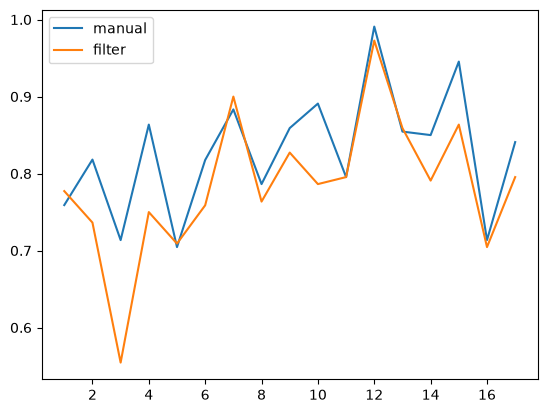

In [63]:
plt.plot(range(1,18),manual_score,label="manual")
plt.plot(range(1,18),filter_score,label="filter")
plt.legend()
plt.show()